Обработка изображений
Взять произвольное изображение. Поместить в центр рисунка белый квадрат, занимающий 10% площади рисунка.

Размер изображения: 600x400
Размер стороны квадрата: 154 px
Координаты квадрата: (223, 123) до (377, 277)


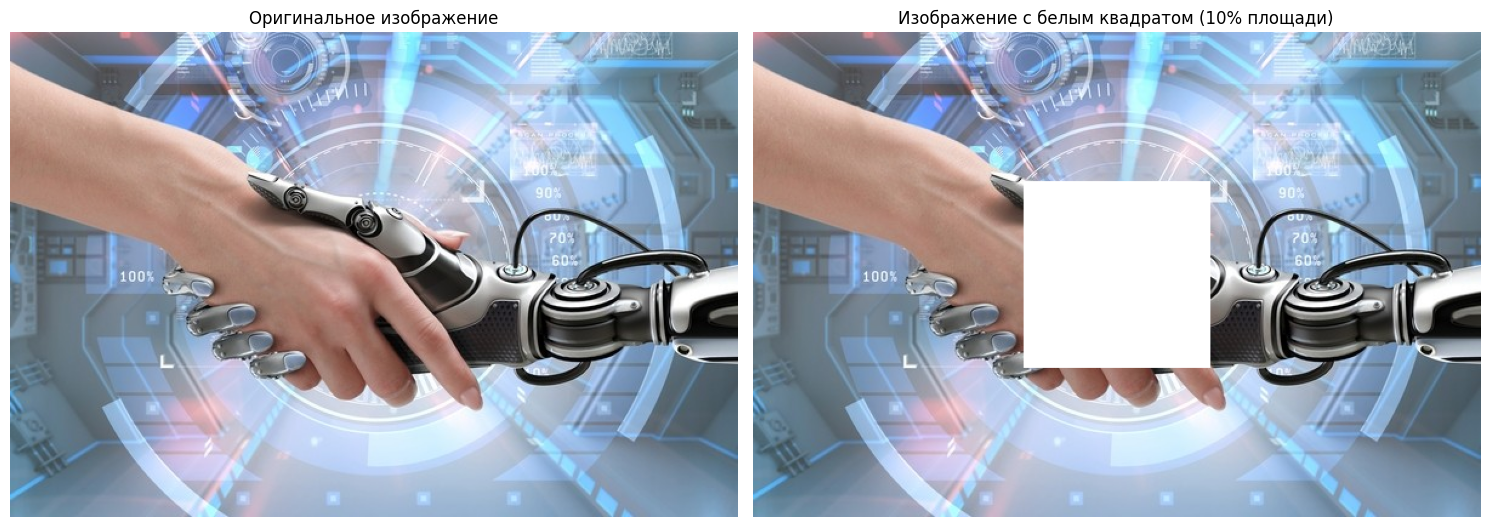

In [ ]:
import matplotlib.pyplot as plt
from skimage.io import imread
import numpy as np

url = 'https://www.osp.ru/FileStorage/DOCUMENTS_ILLUSTRATIONS/13234504/original.jpg'
img = imread(url)

height, width = img.shape[:2]
print(f'Размер изображения: {width}x{height}')

side = int(np.sqrt(0.1 * width * height))
print(f'Размер стороны квадрата: {side} px')

center_x = width // 2
center_y = height // 2

x1 = center_x - side // 2
y1 = center_y - side // 2
x2 = x1 + side
y2 = y1 + side

print(f'Координаты квадрата: ({x1}, {y1}) до ({x2}, {y2})')

img_with_square = img.copy()

if len(img.shape) == 3:
    img_with_square[y1:y2, x1:x2] = 255
else:
    img_with_square[y1:y2, x1:x2] = 255

plt.figure(figsize=(15, 10))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_with_square)
plt.title('Изображение с белым квадратом (10% площади)')
plt.axis('off')

plt.tight_layout()
plt.show()

Обработка видео
Взять произвольный видеофайл. Поместить в случайном месте каждого кадра видеопотока белый кварат со стороной 50 px.

In [ ]:
import cv2
import numpy as np
import random

!wget -q http://thinkingform.com/wp-content/uploads/2017/09/video-sample-mp4.mp4 -O video-sample.mp4

capture = cv2.VideoCapture('video-sample.mp4')

width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(capture.get(cv2.CAP_PROP_FPS))

print(f'Размер видео: {width}x{height}, FPS: {fps}')

codec = cv2.VideoWriter_fourcc(*'MP4V')
output = cv2.VideoWriter('output_with_squares.mp4', codec, fps, (width, height))

frame_count = 0
while True:
    ret, frame = capture.read()
    if not ret:
        break

    x = random.randint(0, width - 50)
    y = random.randint(0, height - 50)

    frame[y:y+50, x:x+50] = [255, 255, 255]

    output.write(frame)
    frame_count += 1

    if frame_count % 30 == 0:
        print(f'Обработано кадров: {frame_count}')

capture.release()
output.release()

print(f'Готово! Обработано {frame_count} кадров.')
print('Результат сохранен в output_with_squares.mp4')


Размер видео: 560x320, FPS: 30
Обработано кадров: 30
Обработано кадров: 60
Обработано кадров: 90
Обработано кадров: 120
Обработано кадров: 150
Готово! Обработано 166 кадров.
Результат сохранен в output_with_squares.mp4


In [ ]:
import matplotlib.pyplot as plt
import imageio
import matplotlib.animation as animation
from IPython.display import HTML

def display_video(video):
    fig = plt.figure(figsize=(12, 7))
    mov = []
    for i in range(len(video)):
        img = plt.imshow(video[i], animated=True)
        plt.axis('off')
        mov.append([img])

    anime = animation.ArtistAnimation(fig, mov, interval=50, repeat_delay=1000)
    plt.close()
    return anime

video = imageio.mimread('output_with_squares.mp4')
HTML(display_video(video).to_html5_video())

Обработка аудиофайла
Найти в обучающем наборе esc50-dataset WAV файл с лаем собаки;
визуально по графику амплитуды звуковой волны найти участок файла непосредственно содержащий звук лая;
построить спектрограмму для найденного участка;
подумать (и реализовать), как с помощью цифрового представления звука можно автоматизировать удаление части файла, не содержащего полезной информации.

Найдено файлов с лаем собаки: 40
Используем файл: 1-100032-A-0.wav
Частота дискретизации: 44100 Hz
Длительность: 5.00 секунд

Воспроизведение аудио:


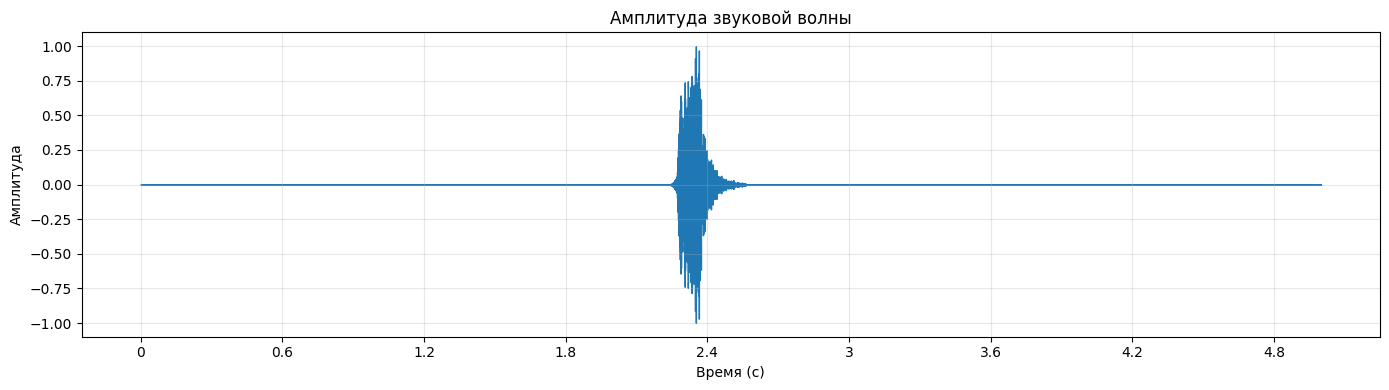


Порог обнаружения: 0.089162


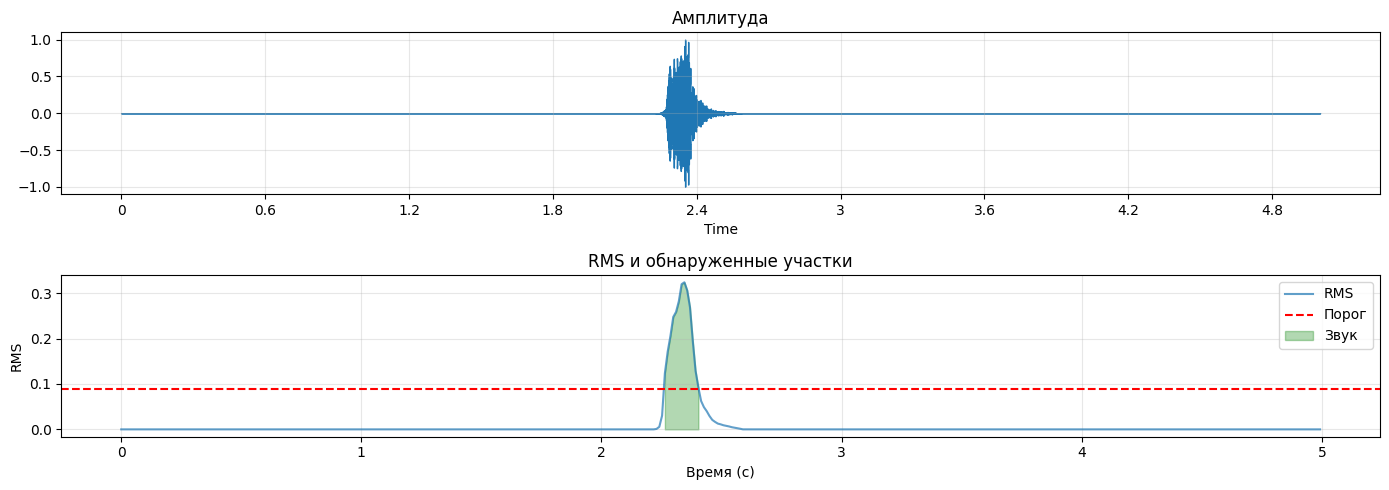


Найдено 1 звуковых участков
Самый громкий участок: 2.26с - 2.41с


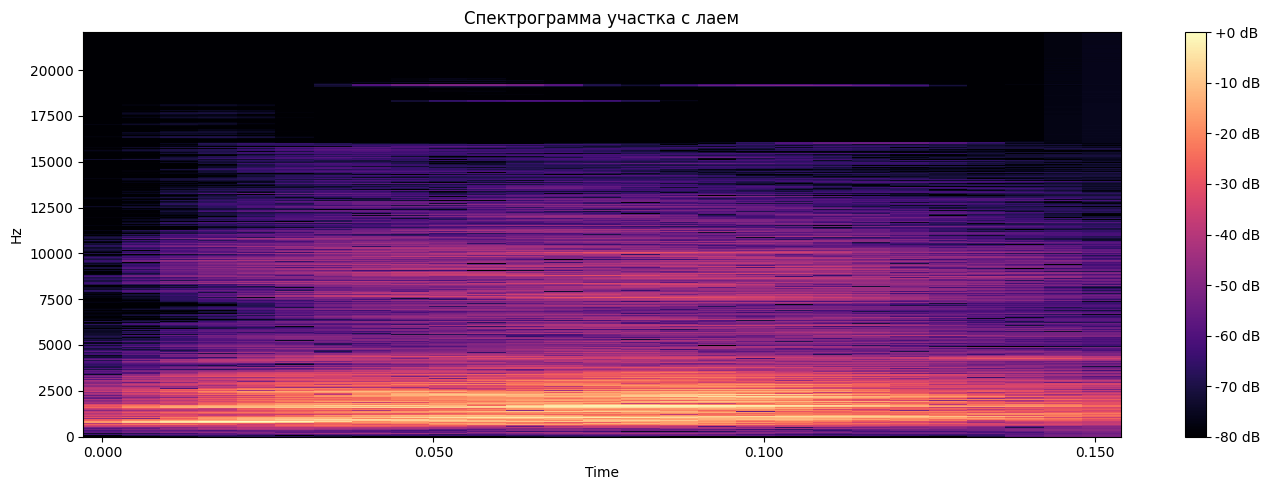


Результат удаления тишины
Оригинал: 5.00 с
После обработки: 0.15 с
Удалено: 97.1%
Участков: 1


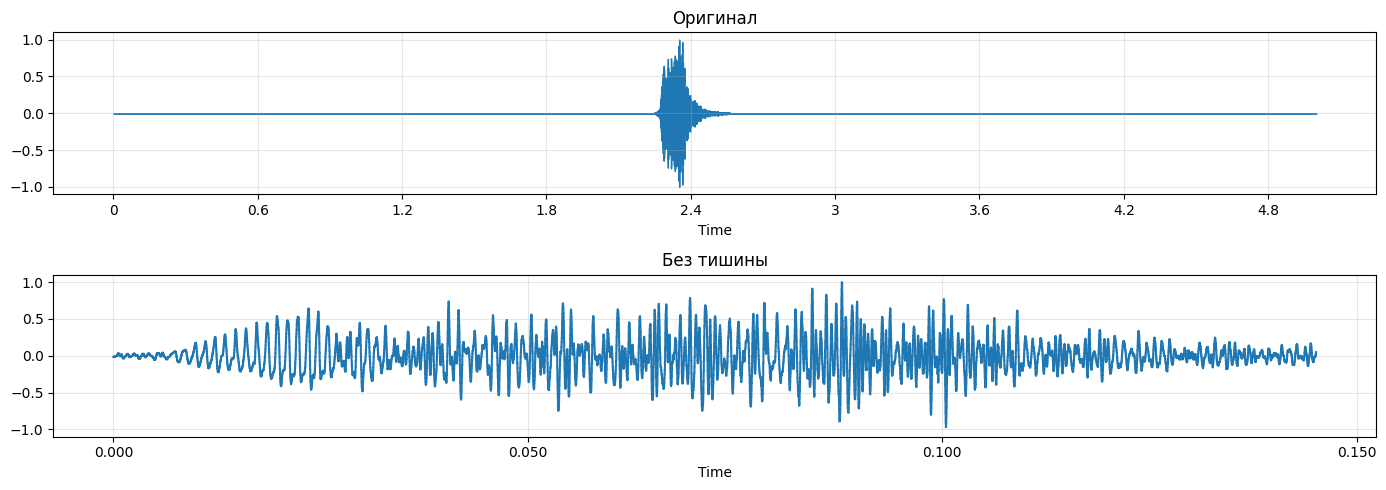


Сохранено: bark_no_silence.wav


In [ ]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io import wavfile
import pandas as pd
import os

meta_path = 'ESC-50-master/meta/esc50.csv'
df = pd.read_csv(meta_path)

dog_df = df[df['target'] == 0]
dog_files = dog_df['filename'].tolist()

print(f'Найдено файлов с лаем собаки: {len(dog_files)}')

if len(dog_files) > 0:
    audio_file = dog_files[0]
    esc50_path = 'ESC-50-master/audio'
    audio_path = os.path.join(esc50_path, audio_file)
    print(f'Используем файл: {audio_file}')

    sample_rate, data = wavfile.read(audio_path)

    if data.dtype == np.int16:
        data = data / 32768.0
    elif data.dtype == np.int32:
        data = data / 2147483648.0

    print(f'Частота дискретизации: {sample_rate} Hz')
    print(f'Длительность: {len(data) / sample_rate:.2f} секунд')

    print('\nВоспроизведение аудио:')
    ipd.Audio(data=data, rate=sample_rate)

    plt.figure(figsize=(14, 4))
    librosa.display.waveshow(data, sr=sample_rate)
    plt.title('Амплитуда звуковой волны')
    plt.xlabel('Время (с)')
    plt.ylabel('Амплитуда')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    hop_length = 512
    rms = librosa.feature.rms(y=data, hop_length=hop_length)[0]
    times = np.arange(len(rms)) * hop_length / sample_rate

    threshold = np.mean(rms) + 2 * np.std(rms)
    loud_sections = rms > threshold

    print(f'\nПорог обнаружения: {threshold:.6f}')

    plt.figure(figsize=(14, 5))

    plt.subplot(2, 1, 1)
    librosa.display.waveshow(data, sr=sample_rate)
    plt.title('Амплитуда')
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 1, 2)
    plt.plot(times, rms, label='RMS', alpha=0.7)
    plt.axhline(y=threshold, color='r', linestyle='--', label='Порог')
    plt.fill_between(times, rms, where=loud_sections, color='green', alpha=0.3, label='Звук')
    plt.title('RMS и обнаруженные участки')
    plt.xlabel('Время (с)')
    plt.ylabel('RMS')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    if np.any(loud_sections):
        loud_indices = np.where(loud_sections)[0]
        sections = []
        in_section = False
        start_idx = 0

        for i, is_loud in enumerate(loud_sections):
            if is_loud and not in_section:
                in_section = True
                start_idx = i
            elif not is_loud and in_section:
                in_section = False
                end_idx = i
                sections.append((start_idx * hop_length, end_idx * hop_length))

        if in_section:
            sections.append((start_idx * hop_length, len(loud_sections) * hop_length))

        print(f'\nНайдено {len(sections)} звуковых участков')

        max_rms = 0
        best_section = sections[0]

        for start, end in sections:
            segment = data[start:end]
            segment_rms = np.sqrt(np.mean(segment**2))
            if segment_rms > max_rms:
                max_rms = segment_rms
                best_section = (start, end)

        start_sample, end_sample = best_section
        bark_section = data[start_sample:end_sample]

        print(f'Самый громкий участок: {start_sample/sample_rate:.2f}с - {end_sample/sample_rate:.2f}с')

        ipd.Audio(data=bark_section, rate=sample_rate)

        X = librosa.stft(bark_section, n_fft=2048, hop_length=256)
        X_db = librosa.amplitude_to_db(abs(X), ref=np.max)

        plt.figure(figsize=(14, 5))
        librosa.display.specshow(X_db, sr=sample_rate, hop_length=256,
                                x_axis='time', y_axis='hz')
        plt.colorbar(format='%+2.0f dB')
        plt.title('Спектрограмма участка с лаем')
        plt.tight_layout()
        plt.show()

    def remove_silence(audio, sample_rate, threshold_factor=2.0, min_duration=0.1):
        hop_length = 256
        rms = librosa.feature.rms(y=audio, hop_length=hop_length)[0]
        threshold = np.mean(rms) + threshold_factor * np.std(rms)
        loud = rms > threshold

        sections = []
        in_sec = False
        start = 0

        for i, is_loud in enumerate(loud):
            if is_loud and not in_sec:
                in_sec = True
                start = i
            elif not is_loud and in_sec:
                in_sec = False
                end = i
                if (end - start) * hop_length / sample_rate >= min_duration:
                    sections.append((start * hop_length, end * hop_length))

        if in_sec and (len(loud) - start) * hop_length / sample_rate >= min_duration:
            sections.append((start * hop_length, len(loud) * hop_length))

        trimmed = np.concatenate([audio[s:e] for s, e in sections])
        return trimmed, sections

    trimmed, sections = remove_silence(data, sample_rate, threshold_factor=2.0, min_duration=0.1)

    print(f'\n{"="*50}')
    print('Результат удаления тишины')
    print(f'{"="*50}')
    print(f'Оригинал: {len(data)/sample_rate:.2f} с')
    print(f'После обработки: {len(trimmed)/sample_rate:.2f} с')
    print(f'Удалено: {100*(1-len(trimmed)/len(data)):.1f}%')
    print(f'Участков: {len(sections)}')

    ipd.Audio(data=trimmed, rate=sample_rate)

    plt.figure(figsize=(14, 5))

    plt.subplot(2, 1, 1)
    librosa.display.waveshow(data, sr=sample_rate)
    plt.title('Оригинал')
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 1, 2)
    librosa.display.waveshow(trimmed, sr=sample_rate)
    plt.title('Без тишины')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    from scipy.io.wavfile import write
    write('bark_no_silence.wav', sample_rate, (trimmed * 32767).astype(np.int16))
    print('\nСохранено: bark_no_silence.wav')

else:
    print('Файлы с лаем не найдены')


Визуализация временного ряда
Зарегистрируйтесь на сайте openweathermap.org и получите свой ключ для автоматизации действий;
исследуйте структуру json ответа сайта и найти поля с температурой, влажностью и давлением;
соберите данные об изменении температуры, влажности и давления по любому городу за 3 дня;
автоматизруте запросы к сайту раз в час, сохраняйте данные во внешний файл, чтобы они не потерялись при перезагрузке виртуальной машины google colab;
постройте с помощью библиотреки matplotlib на одном рисунке графики изменения всех наблюдаемых характеристик (маштабируйте по оси y разные величины, так чтобы графики были наглядные). Оформите красиво подписи осей (с днями и часами измерений), легенду графиков.

Начинаем сбор данных через API v2.5 для Казани
Координаты: 55.7887, 49.1221

[1/3] Запрос...
  Температура: 4.3°C
  Влажность: 79%
  Давление: 1016 гПа

[2/3] Запрос...
  Температура: 4.2°C
  Влажность: 79%
  Давление: 1016 гПа

[3/3] Запрос...
  Температура: 4.2°C
  Влажность: 79%
  Давление: 1016 гПа


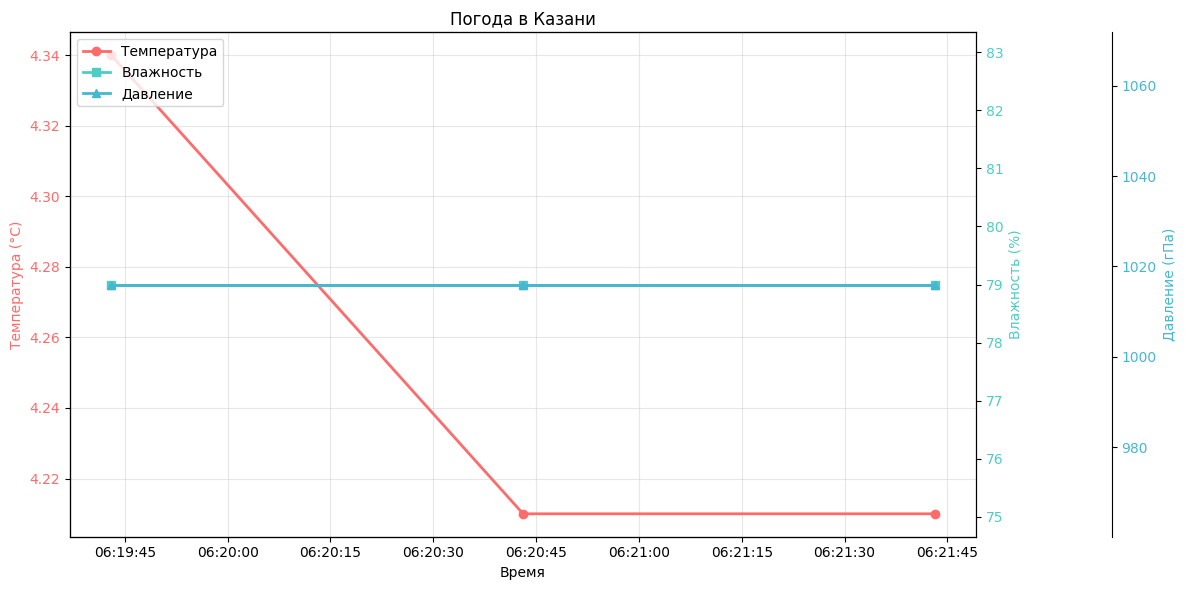


Данные сохранены в weather_data.csv


In [ ]:
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
from datetime import datetime

LAT = 55.7887
LON = 49.1221
API_KEY = os.environ["OPENWEATHER_API_KEY"]  # ключ не хранится в коде
OUTPUT_FILE = 'weather_data.csv'

def get_weather_v25(lat, lon, api_key):
    url = f'https://api.openweathermap.org/data/2.5/weather?lat={lat}&lon={lon}&units=metric&lang=ru&appid={api_key}'

    try:
        response = requests.get(url)
        response.raise_for_status()
        data = response.json()

        weather_data = {
            'timestamp': datetime.now().isoformat(),
            'temperature': data['main']['temp'],
            'feels_like': data['main']['feels_like'],
            'humidity': data['main']['humidity'],
            'pressure': data['main']['pressure'],
            'description': data['weather'][0]['description'],
            'wind_speed': data['wind']['speed'],
            'lat': lat,
            'lon': lon
        }

        return weather_data

    except requests.exceptions.RequestException as e:
        print(f'Ошибка: {e}')
        if hasattr(e, 'response') and e.response:
            print(f'Ответ: {e.response.text}')
        return None

print(f'Координаты: {LAT}, {LON}')

df = pd.DataFrame()
num_measurements = 3

for i in range(num_measurements):
    print(f'\n[{i+1}/{num_measurements}] Запрос...')

    weather = get_weather_v25(LAT, LON, API_KEY)

    if weather:
        print(f"  Температура: {weather['temperature']:.1f}°C")
        print(f"  Влажность: {weather['humidity']}%")
        print(f"  Давление: {weather['pressure']} гПа")

        new_row = pd.DataFrame([weather])
        df = pd.concat([df, new_row], ignore_index=True)
        df.to_csv(OUTPUT_FILE, index=False)
    else:
        print('  Ошибка')

    if i < num_measurements - 1:
        time.sleep(60)

# Визуализация
if len(df) > 0:
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.set_xlabel('Время')
    ax1.set_ylabel('Температура (°C)', color='#ff6b6b')
    ax1.plot(df['timestamp'], df['temperature'], color='#ff6b6b', marker='o', linewidth=2, label='Температура')
    ax1.tick_params(axis='y', labelcolor='#ff6b6b')
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    ax2.set_ylabel('Влажность (%)', color='#4ecdc4')
    ax2.plot(df['timestamp'], df['humidity'], color='#4ecdc4', marker='s', linewidth=2, label='Влажность')
    ax2.tick_params(axis='y', labelcolor='#4ecdc4')

    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("axes", 1.15))
    ax3.set_ylabel('Давление (гПа)', color='#45b7d1')
    ax3.plot(df['timestamp'], df['pressure'], color='#45b7d1', marker='^', linewidth=2, label='Давление')
    ax3.tick_params(axis='y', labelcolor='#45b7d1')

    lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines()
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left')

    plt.title('Погода в Казани')
    plt.tight_layout()
    plt.show()

    print(f'\nДанные сохранены в {OUTPUT_FILE}')
else:
    print('Нет данных')